<a href="https://www.kaggle.com/code/manahil12/retail-sales-data-analysis-by-manahil-tahir?scriptVersionId=367055683" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/engraamirjamil/retail-sales-dataset-for-data-preprocessing/sales_dataset_89984_records_23_features.csv


<div style="background-color: #000080; color: white; padding: 25px; text-align: center; border-radius: 10px; font-size:25px;">
    <h1 style="color: white; margin: 0; padding-bottom: 8px;">Retail Sales Data Analysis</h1>
    <p style="margin: 0; font-size: 16px; font-weight: bold; text-align: right;">By: Manahil Tahir</p>
</div>

## 1. Project Overview
 
**Project Objective**
         The primary objective of this project is to perform comprehensive data cleaning, preprocessing, and exploratory data analysis (EDA) on retail sales data. The analysis focuses on improving data quality, identifying sales trends, evaluating business performance, and generating meaningful insights to support data-driven decision-making.

### Project Scope

- **Data Cleaning:** Handle missing values, duplicates, and inconsistencies.
- **Data Validation:** Identify invalid entries and outliers.
- **Data Preprocessing:** Prepare and structure data for accurate analysis.
- **Exploratory Data Analysis:** Examine patterns, trends, and relationships.
- **Sales Analysis:** Evaluate sales performance across products, categories, and regions.
- **Customer Analysis:** Understand customer purchasing behavior and demographics.
- **Business Intelligence:** Develop actionable insights and recommendations.

### Tools and Technologies

- **Python**  - Data analysis and processing
- **Jupyter Notebook** - Interactive development environment
- **Pandas** - Data manipulation and analysis
- **NumPy** - Numerical computations
- **Matplotlib** - Data visualization
- **Seaborn** - Statistical visualization

## 2. Import and Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Dataset Loading

In [3]:
df = pd.read_csv("/kaggle/input/datasets/engraamirjamil/retail-sales-dataset-for-data-preprocessing/sales_dataset_89984_records_23_features.csv")

## 4. Data Inspection

In [4]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Age,Gender,City,Region,Customer_Segment,Sales_Channel,Product_ID,...,Quantity,Discount_Percent,Shipping_Cost,Payment_Method,Order_Status,Return_Flag,Marketing_Channel,Customer_Rating,Sales_Amount,Profit_Margin
0,ORD-0000001,2024-01-09,CUS-020443,64.0,Female,Karachi,Sindh,Corporate,Retail Store,PRD-018,...,2.0,8.33,119.36,Credit Card,Delivered,No,Direct,5.0,6987.71,27.20
1,ORD-0000002,2025-06-13,CUS-025451,40.0,Male,Rawalpindi,Punjab,New,Marketplace,PRD-011,...,1.0,9.38,167.96,Cash on Delivery,Delivered,No,Social Media,5.0,3976.91,31.46
2,ORD-0000003,2025-09-25,CUS-022569,56.0,Male,Lahore,Punjab,Returning,Marketplace,PRD-021,...,5.0,17.63,250.01,Debit Card,Delivered,No,Search,3.0,11467.71,30.81
3,ORD-0000004,2024-01-01,CUS-010322,31.0,male,Rawalpindi,Punjab,Loyal,Marketplace,PRD-017,...,3.0,8.10,NaN,Cash on Delivery,Delivered,No,Direct,5.0,69182.12,25.20
4,ORD-0000005,2024-01-29,CUS-008308,42.0,Female,Gujranwala,Punjab,Loyal,Marketplace,PRD-012,...,4.0,15.37,348.78,Cash on Delivery,Delivered,No,Social Media,NaN,10489.07,26.54


In [5]:
df.shape

(89984, 23)

In [6]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Age', 'Gender',
       'City', 'Region', 'Customer_Segment', 'Sales_Channel', 'Product_ID',
       'Product_Category', 'Product_Name', 'Unit_Price', 'Quantity',
       'Discount_Percent', 'Shipping_Cost', 'Payment_Method', 'Order_Status',
       'Return_Flag', 'Marketing_Channel', 'Customer_Rating', 'Sales_Amount',
       'Profit_Margin'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89984 entries, 0 to 89983
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           89984 non-null  object 
 1   Order_Date         89984 non-null  object 
 2   Customer_ID        89984 non-null  object 
 3   Customer_Age       85018 non-null  float64
 4   Gender             86823 non-null  object 
 5   City               87779 non-null  object 
 6   Region             89984 non-null  object 
 7   Customer_Segment   85863 non-null  object 
 8   Sales_Channel      88309 non-null  object 
 9   Product_ID         89984 non-null  object 
 10  Product_Category   88905 non-null  object 
 11  Product_Name       88312 non-null  object 
 12  Unit_Price         87468 non-null  float64
 13  Quantity           88986 non-null  float64
 14  Discount_Percent   85926 non-null  float64
 15  Shipping_Cost      83205 non-null  float64
 16  Payment_Method     840

## 5. Statistical Analysis

In [8]:
df.dtypes

Order_ID              object
Order_Date            object
Customer_ID           object
Customer_Age         float64
Gender                object
City                  object
Region                object
Customer_Segment      object
Sales_Channel         object
Product_ID            object
Product_Category      object
Product_Name          object
Unit_Price           float64
Quantity             float64
Discount_Percent     float64
Shipping_Cost        float64
Payment_Method        object
Order_Status          object
Return_Flag           object
Marketing_Channel     object
Customer_Rating      float64
Sales_Amount         float64
Profit_Margin        float64
dtype: object

In [9]:
df.describe()

,Customer_Age,Unit_Price,Quantity,Discount_Percent,Shipping_Cost,Customer_Rating,Sales_Amount,Profit_Margin
count,85018.000000,87468.000000,88986.000000,85926.000000,83205.000000,67426.000000,89984.000000,86760.000000
mean,36.332188,4699.456392,2.387241,9.954825,221.181041,4.002951,9833.836277,24.284637
std,11.398236,4586.077443,1.753613,6.674144,104.789631,0.879313,10889.426412,8.174829
min,0.000000,-250.000000,-3.000000,-5.000000,0.000000,-1.000000,555.860000,-13.800000
25%,28.000000,2139.465000,1.000000,4.900000,149.180000,3.000000,3727.130000,18.700000
50%,36.000000,3593.665000,2.000000,8.725000,221.600000,4.000000,6644.590000,25.020000
75%,44.000000,5826.925000,3.000000,13.720000,292.700000,5.000000,11827.665000,30.250000
max,132.000000,233600.870000,114.000000,125.000000,764.570000,7.000000,178951.920000,50.730000


## 6. Checking Missing Values

In [10]:
df.isnull().sum()

Order_ID                 0
Order_Date               0
Customer_ID              0
Customer_Age          4966
Gender                3161
City                  2205
Region                   0
Customer_Segment      4121
Sales_Channel         1675
Product_ID               0
Product_Category      1079
Product_Name          1672
Unit_Price            2516
Quantity               998
Discount_Percent      4058
Shipping_Cost         6779
Payment_Method        5959
Order_Status          2020
Return_Flag              0
Marketing_Channel     7619
Customer_Rating      22558
Sales_Amount             0
Profit_Margin         3224
dtype: int64

### Handling Missing Values

In [11]:
df_clean = df.copy()

In [12]:
numeric_columns = ['Customer_Age', 'Unit_Price', 'Quantity',
                   'Discount_Percent', 'Shipping_Cost', 'Profit_Margin']

for column in numeric_columns:
    if column in df_clean.columns:
        df_clean[column] = df_clean[column].fillna(df_clean[column].median())

In [13]:
category_columns = ['Gender', 'City', 'Customer_Segment', 'Sales_Channel',
                    'Product_Category', 'Product_Name', 'Payment_Method',
                    'Order_Status', 'Marketing_Channel']

for column in category_columns:
    if column in df_clean.columns and df_clean[column].notna().any():
        df_clean[column] = df_clean[column].fillna(df_clean[column].mode()[0])

In [14]:
df_clean.isnull().sum()

Order_ID                 0
Order_Date               0
Customer_ID              0
Customer_Age             0
Gender                   0
City                     0
Region                   0
Customer_Segment         0
Sales_Channel            0
Product_ID               0
Product_Category         0
Product_Name             0
Unit_Price               0
Quantity                 0
Discount_Percent         0
Shipping_Cost            0
Payment_Method           0
Order_Status             0
Return_Flag              0
Marketing_Channel        0
Customer_Rating      22558
Sales_Amount             0
Profit_Margin            0
dtype: int64

## 7. Checking Duplicates

In [15]:
df_clean.duplicated().sum()

np.int64(65)

In [16]:
df_clean = df_clean.drop_duplicates()

In [17]:
df_clean.duplicated().sum()

np.int64(0)

## 8. Inconsistent Categories

In [18]:
category_columns = ['Gender', 'City', 'Region', 'Customer_Segment',
                    'Sales_Channel', 'Product_Category', 'Payment_Method',
                    'Order_Status', 'Marketing_Channel']

for column in category_columns:
    if column in df_clean.columns:
        print('\n', column)
        print(df_clean[column].dropna().unique()[:30])


 Gender
['Female' 'Male' 'male' 'Prefer not to say' 'Non-binary' 'F' 'female' 'M'
 ' MALE ' ' FEMALE ']

 City
['Karachi' 'Rawalpindi' 'Lahore' 'Gujranwala' 'Islamabad' 'Hyderabad'
 'Sialkot' 'Faisalabad' 'Quetta' 'Peshawar' 'Multan' 'Abbottabad'
 'karachi' ' KARACHI ' ' LAHORE ' 'lahore' ' Rawalpindi ' 'rawalpindi']

 Region
['Sindh' 'Punjab' 'Islamabad Capital Territory' 'Balochistan'
 'Khyber Pakhtunkhwa']

 Customer_Segment
['Corporate' 'New' 'Returning' 'Loyal' 'returning' ' LOYAL ' ' RETURNING '
 'loyal']

 Sales_Channel
['Retail Store' 'Marketplace' 'Online' 'Phone Order' ' ONLINE '
 'retail store' 'online' ' RETAIL STORE ' 'E-commerce' 'Retail']

 Product_Category
['Office Supplies' 'Home & Kitchen' 'Toys & Games' 'Beauty' 'Clothing'
 'Accessories' 'Stationery' 'Electronics']

 Payment_Method
['Credit Card' 'Cash on Delivery' 'Debit Card' 'Digital Wallet'
 'Bank Transfer' 'digital wallet' ' CASH ON DELIVERY ' 'COD' 'Wallet'
 'cash on delivery' ' DIGITAL WALLET ']

 Order_Statu

## 9. Invalid Values

In [19]:
df_clean[df_clean['Customer_Age'] <= 0][['Customer_Age']].head(10)

,Customer_Age
6172,0.0
36740,0.0
40555,0.0
46319,0.0
53949,0.0
56800,0.0
65071,0.0
74712,0.0
84938,0.0


In [20]:
df_clean[df_clean['Customer_Age'] > 100][['Customer_Age']].head(10)

,Customer_Age
556,132.0
770,105.0
1497,105.0
3323,105.0
15300,132.0
27423,132.0
41045,132.0
44295,105.0
47930,105.0
52571,105.0


In [21]:
df_clean[df_clean['Unit_Price'] <= 0][['Unit_Price', 'Sales_Amount']].head(10)

,Unit_Price,Sales_Amount
806,-250.0,7479.24
7561,-1.0,3447.81
15907,-250.0,2500.42
19072,-1.0,10085.33
19553,-250.0,4004.38
36474,-250.0,18181.68
38674,0.0,4093.65
42384,-1.0,6929.71
42432,-250.0,2720.55
43211,-250.0,45899.76


In [22]:
df_clean[df_clean['Quantity'] <= 0][['Quantity']].head(10)

,Quantity
1186,-1.0
4306,-1.0
5743,0.0
10399,-1.0
10666,0.0
16589,-1.0
17537,0.0
21627,0.0
21631,0.0
22089,-3.0


### Correcting clearly invalid customer ages

Zero age and ages above 100 are treated as suspicious for this assignment and replaced with the median age. Age 7 is not automatically changed because it may be possible. Non-positive unit prices and quantities are displayed for review rather than automatically changed, because their correct values cannot be known from these values alone.

In [23]:
age_median = df_clean['Customer_Age'].median()
df_clean.loc[(df_clean['Customer_Age'] <= 0) | (df_clean['Customer_Age'] > 100),
             'Customer_Age'] = age_median

In [24]:
df_clean['Customer_Age'].describe()

count    89919.000000
mean        36.301015
std         11.011130
min          7.000000
25%         28.000000
50%         36.000000
75%         44.000000
max         78.000000
Name: Customer_Age, dtype: float64

## 10. Checking Outliers

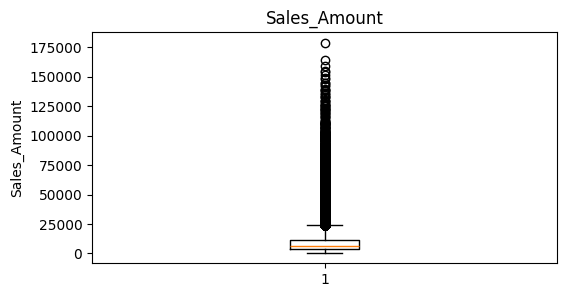

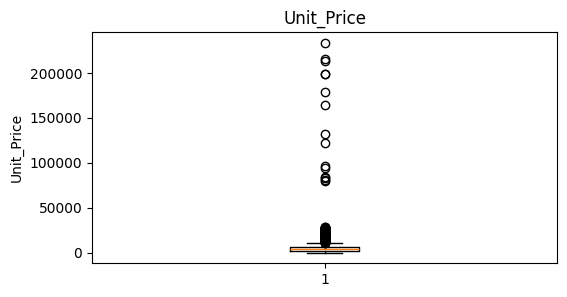

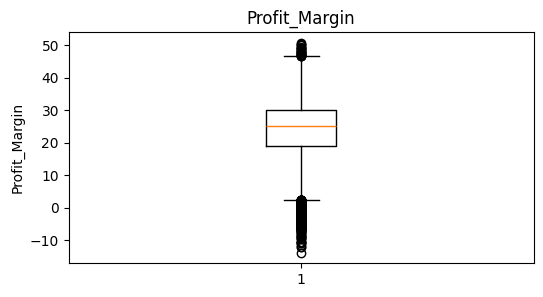

In [25]:
numeric_columns = ['Sales_Amount', 'Unit_Price', 'Profit_Margin']

for column in numeric_columns:
    if column in df_clean.columns:
        plt.figure(figsize=(6, 3))
        plt.boxplot(df_clean[column].dropna())
        plt.title(column)
        plt.ylabel(column)
        plt.show()

## 11. Final Validation Checking

In [26]:
df_clean.shape

(89919, 23)

In [27]:
df_clean.isnull().sum()

Order_ID                 0
Order_Date               0
Customer_ID              0
Customer_Age             0
Gender                   0
City                     0
Region                   0
Customer_Segment         0
Sales_Channel            0
Product_ID               0
Product_Category         0
Product_Name             0
Unit_Price               0
Quantity                 0
Discount_Percent         0
Shipping_Cost            0
Payment_Method           0
Order_Status             0
Return_Flag              0
Marketing_Channel        0
Customer_Rating      22543
Sales_Amount             0
Profit_Margin            0
dtype: int64

In [28]:
df_clean.duplicated().sum()

np.int64(0)

In [29]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 89919 entries, 0 to 89983
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           89919 non-null  object 
 1   Order_Date         89919 non-null  object 
 2   Customer_ID        89919 non-null  object 
 3   Customer_Age       89919 non-null  float64
 4   Gender             89919 non-null  object 
 5   City               89919 non-null  object 
 6   Region             89919 non-null  object 
 7   Customer_Segment   89919 non-null  object 
 8   Sales_Channel      89919 non-null  object 
 9   Product_ID         89919 non-null  object 
 10  Product_Category   89919 non-null  object 
 11  Product_Name       89919 non-null  object 
 12  Unit_Price         89919 non-null  float64
 13  Quantity           89919 non-null  float64
 14  Discount_Percent   89919 non-null  float64
 15  Shipping_Cost      89919 non-null  float64
 16  Payment_Method     89919 no

## 12. Exploratory Data Analysis (EDA)

### 12.1 Sales Summary

In [30]:
df_clean['Sales_Amount'].describe()

count     89919.000000
mean       9834.847495
std       10892.046967
min         555.860000
25%        3726.970000
50%        6644.020000
75%       11829.090000
max      178951.920000
Name: Sales_Amount, dtype: float64

### 12.2 Sales by Product Category

Product_Category
Electronics        2.388461e+08
Home & Kitchen     1.582070e+08
Clothing           1.534923e+08
Office Supplies    1.340520e+08
Beauty             9.837543e+07
Accessories        4.426185e+07
Toys & Games       4.319460e+07
Stationery         1.391042e+07
Name: Sales_Amount, dtype: float64


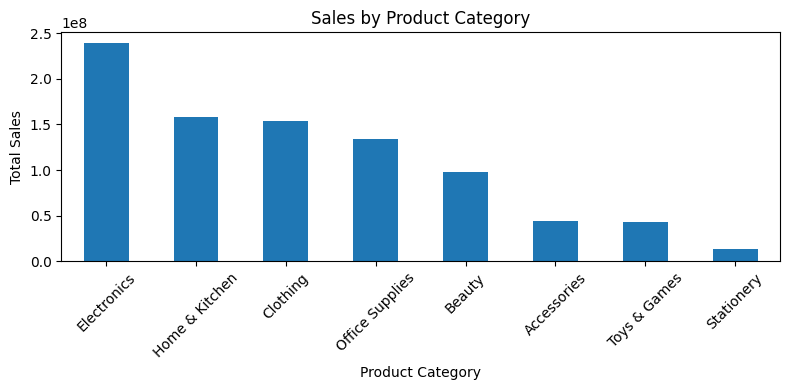

In [31]:
sales_by_category = df_clean.groupby('Product_Category')['Sales_Amount'].sum().sort_values(ascending=False)
print(sales_by_category)
sales_by_category.plot(kind='bar', figsize=(8, 4))
plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 12.3 Sales by Region

Region
Punjab                         4.524764e+08
Sindh                          2.327664e+08
Khyber Pakhtunkhwa             8.863675e+07
Islamabad Capital Territory    7.986885e+07
Balochistan                    3.059124e+07
Name: Sales_Amount, dtype: float64


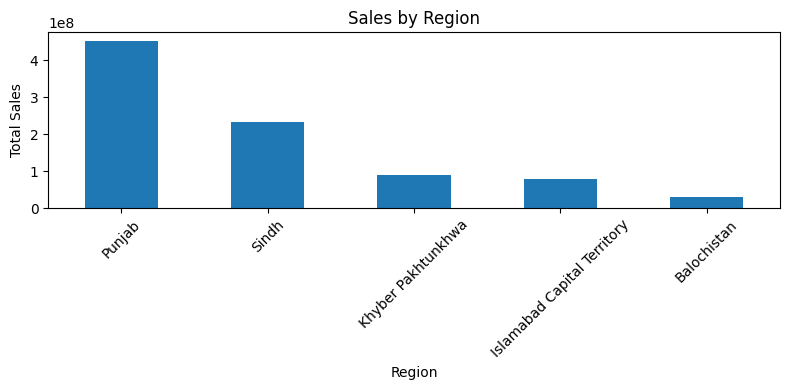

In [32]:
sales_by_region = df_clean.groupby('Region')['Sales_Amount'].sum().sort_values(ascending=False)
print(sales_by_region)
sales_by_region.plot(kind='bar', figsize=(8, 4))
plt.title('Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 12.4 Sales by Gender

Gender
Male                 4.269625e+08
Female               3.873820e+08
Prefer not to say    2.892195e+07
Non-binary           1.300086e+07
male                 5.053962e+06
 FEMALE              4.971741e+06
F                    4.662568e+06
 MALE                4.585320e+06
female               4.540038e+06
M                    4.258672e+06
Name: Sales_Amount, dtype: float64


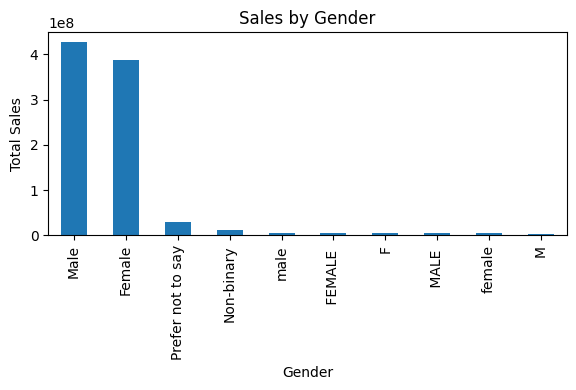

In [33]:
sales_by_gender = df_clean.groupby('Gender')['Sales_Amount'].sum().sort_values(ascending=False)
print(sales_by_gender)
sales_by_gender.plot(kind='bar', figsize=(6, 4))
plt.title('Sales by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

### 12.5 Best-Selling Product Categories by Quantity

Product_Category
Electronics        43825.0
Clothing           41578.0
Home & Kitchen     34529.0
Beauty             25110.0
Stationery         19866.0
Accessories        19071.0
Toys & Games       16115.0
Office Supplies    14186.0
Name: Quantity, dtype: float64


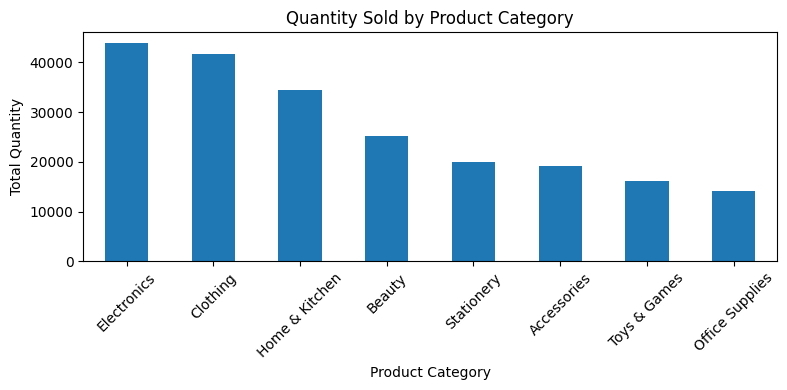

In [34]:
quantity_by_category = df_clean.groupby('Product_Category')['Quantity'].sum().sort_values(ascending=False)
print(quantity_by_category)
quantity_by_category.plot(kind='bar', figsize=(8, 4))
plt.title('Quantity Sold by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 12.6 Order Status

Order_Status
Delivered           66771
Shipped              9195
Processing           5804
Cancelled            3291
Returned             2964
Refunded             1389
Return Requested      505
Name: count, dtype: int64


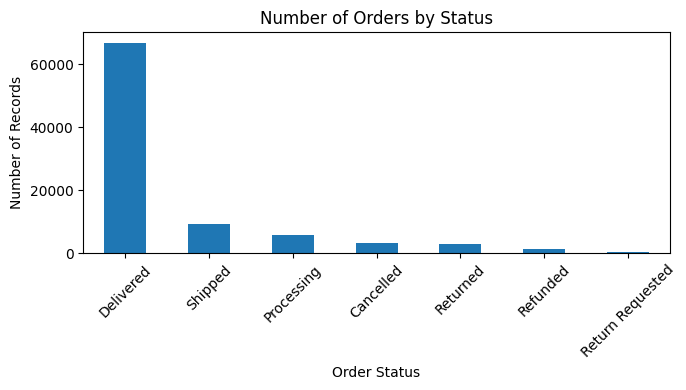

In [35]:
order_status_count = df_clean['Order_Status'].value_counts()
print(order_status_count)
order_status_count.plot(kind='bar', figsize=(7, 4))
plt.title('Number of Orders by Status')
plt.xlabel('Order Status')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 12.7 Sales Over Time

Order_Date
2024-01    34734009.50
2024-02    31480141.09
2024-03    35533629.78
2024-04    34520030.59
2024-05    37083022.98
2024-06    38318974.69
2024-07    38032484.96
2024-08    36969998.28
2024-09    34877238.50
2024-10    35474730.98
2024-11    42950559.18
2024-12    43570645.50
2025-01    34805813.42
2025-02    32273948.41
2025-03    36151762.39
2025-04    35201359.99
2025-05    37189043.40
2025-06    37016621.07
2025-07    39154246.79
2025-08    36230174.17
2025-09    35087365.47
2025-10    36584592.34
2025-11    40375354.90
2025-12    40316584.83
Freq: M, Name: Sales_Amount, dtype: float64


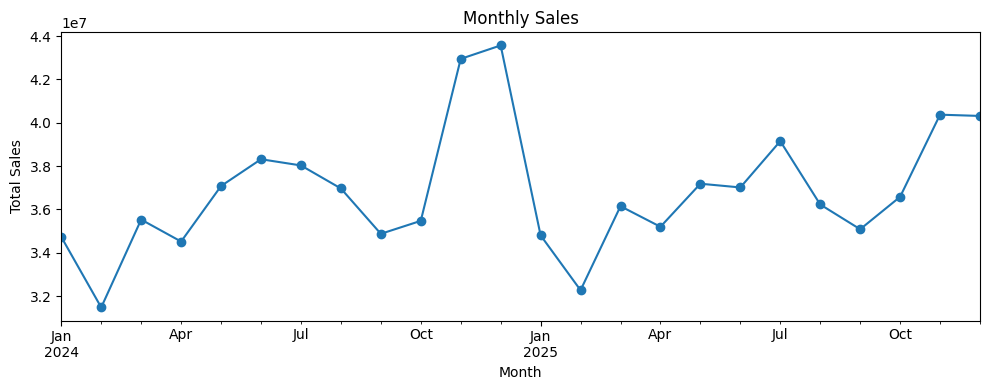

In [36]:
df_clean['Order_Date'] = pd.to_datetime(df_clean['Order_Date'], errors='coerce')
monthly_sales = df_clean.groupby(df_clean['Order_Date'].dt.to_period('M'))['Sales_Amount'].sum()
print(monthly_sales)
monthly_sales.plot(kind='line', figsize=(10, 4), marker='o')
plt.title('Monthly Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

## 13. Key Sales Insights

In [37]:
print('Highest sales category:')
print(sales_by_category.idxmax(), '-', sales_by_category.max())

print('\nHighest sales region:')
print(sales_by_region.idxmax(), '-', sales_by_region.max())

print('\nGender with highest sales:')
print(sales_by_gender.idxmax(), '-', sales_by_gender.max())

Highest sales category:
Electronics - 238846057.47

Highest sales region:
Punjab - 452476412.69

Gender with highest sales:
Male - 426962493.63


## 14. Save Cleaned Dataset

In [38]:
df_clean.to_csv('/kaggle/working/retail_sales_cleaned.csv', index=False)
print('Cleaned dataset saved.')

Cleaned dataset saved.
